In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Source:
    "Источник изотропного излучения фотонов"
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def random_direction(self, E: float) ->np.ndarray:
        """Розыгрыш начального направления"""
        if E < 0:
            raise ValueError("Энергия может быть отрицательной")

        N = int(round(self.Y * E))

        phi = np.random.uniform(0, 2*np.pi, N)
        cosTheta = np.random.uniform(-1, 1, N)
        sinTheta = np.sqrt(1 - cosTheta**2)
        return np.array([sinTheta*np.cos(phi),
                         sinTheta*np.sin(phi),
                         cosTheta])

In [3]:
class Detector:
    "Сферический детектор "

    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        self.p_positions = self.generate_positions()

    def generate_positions(self) -> np.ndarray:
        "Размещение ФЭУ"

        i = np.arange(self.N)
        z = self.R * (1 - 2 * (i + 0.5) / self.N)
        phi = i * np.pi * (3 - np.sqrt(5))
        rho = np.sqrt(self.R**2 - z**2)

        x = rho * np.cos(phi)
        y = rho * np.sin(phi)

        return np.column_stack((x, y, z))

    def is_on_pmt(self, point) -> bool:
        "Проверка принадлежности точки одному из ФЭУ "

        point = np.asarray(point)

        if not np.isclose(np.linalg.norm(point), self.R):
            return False

        distances = np.linalg.norm(
            self.p_positions - point, axis=1
        )

        return bool(np.any(distances <= self.r))

    def intersection(self, position, directions) -> np.ndarray:
        "Точки пересечения фотонов со сферой "
        position = np.asarray(position, dtype= float)

        if np.linalg.norm(position) >= self.R:
            return None

        b = position @ directions

        # Расстояния до поверхности детектора
        t = -b + np.sqrt(b**2 + self.R**2 - np.dot(position, position))

        # Все точки пересечения
        return position[:, None] + directions * t[None, :]

    def photon_hits(self, points) -> np.ndarray:
        "Определяет, в какой фотоумножитель попадёт фотон "
        distances2 = np.sum(
            (points.T[:, None, :] -
             self.p_positions[None, :, :])**2,
            axis=2
        )

        # Ближайший фотоумножитель к каждому фотону
        nearest = np.argmin(distances2, axis=1)

        hits = distances2[
            np.arange(points.shape[1]), nearest
        ] <= self.r**2

        return np.bincount(
            nearest[hits], minlength=self.N
        )

    def photoelectrons(self, n_photons=1):
        "Возвращает случайное число фотоэлектронов по распределению Пуассона со средним a "

        return np.random.poisson(self.a * n_photons)


In [5]:
def simulate_event(E, position):
    directions = source.random_direction(E)
    points = detector.intersection(position, directions)
    n_hits = detector.photon_hits(points)
    n_pe = detector.photoelectrons(n_hits)
    return np.sum(n_pe)


def simulate_events(E, position, n_events=1000):
    "Полный собранный заряд в каждом из независимых событий "
    charges = np.empty(n_events, dtype=int)
    for i in range(n_events):
        charges[i] = simulate_event(E, position)
    return charges


def charge_stats(charges):
    mean = np.mean(charges)
    std = np.std(charges, ddof=1)
    return mean, std, std / mean

In [7]:
source = Source(Y=10000)
detector = Detector(R=2.0, N=40, r=0.1, a=0.5)

E = 1.0
position = np.array([0.0, 0.0, 0.0])


In [8]:
np.random.seed(42)

charges_1 = simulate_events(E=1.0, position=position, n_events=1000)
mean_1, std_1, relative_1 = charge_stats(charges_1)

In [9]:
print(f"Средний заряд: {mean_1:.2f} фотоэлектронов")
print(f"Стандартное отклонение: {std_1:.2f} фотоэлектронов")
print(f"Относительная ширина: {relative_1:.2%}")

Средний заряд: 125.06 фотоэлектронов
Стандартное отклонение: 13.56 фотоэлектронов
Относительная ширина: 10.84%


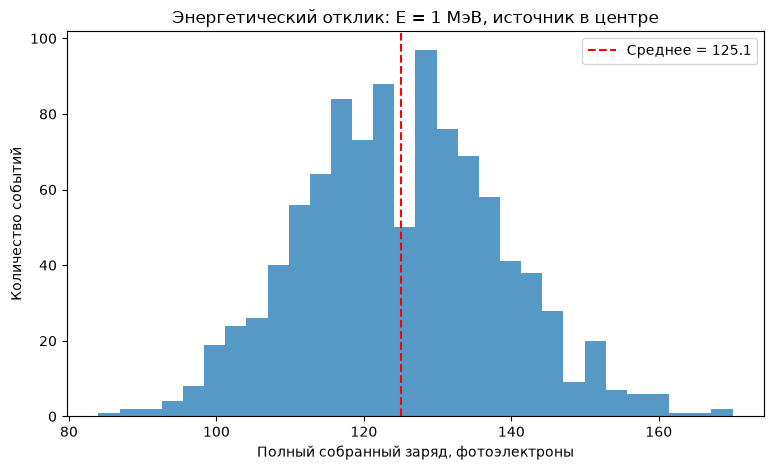

In [12]:
plt.figure(figsize=(9, 5))
plt.hist(charges_1, bins=30, alpha=0.75)
plt.axvline(mean_1, linestyle='--', color='red', label=f'Среднее = {mean_1:.1f}')
plt.xlabel('Полный собранный заряд, фотоэлектроны')
plt.ylabel('Количество событий')
plt.title('Энергетический отклик: E = 1 МэВ, источник в центре')
plt.legend()
plt.show()

In [13]:
energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
results = {1.0: charges_1}

for energy in energies:
    if energy != 1.0:
        results[energy] = simulate_events(E=energy, position=position, n_events=1000)

In [14]:
mean_charges = []
relative_widths = []

print(f"{'E, МэВ':>8} {'Средний Q':>12} {'sigma Q':>12} {'sigma Q / mean Q':>18}")
for energy in energies:
    mean_q, std_q, rel_q = charge_stats(results[energy])
    mean_charges.append(mean_q)
    relative_widths.append(rel_q)
    print(f"{energy:8.1f} {mean_q:12.2f} {std_q:12.2f} {rel_q:18.2%}")

  E, МэВ    Средний Q      sigma Q   sigma Q / mean Q
     0.2        24.86         6.09             24.50%
     0.5        62.93        10.27             16.31%
     0.7        87.22        11.40             13.07%
     1.0       125.06        13.56             10.84%
     1.5       187.85        16.99              9.04%
     2.0       249.20        19.61              7.87%
     3.0       375.40        23.84              6.35%


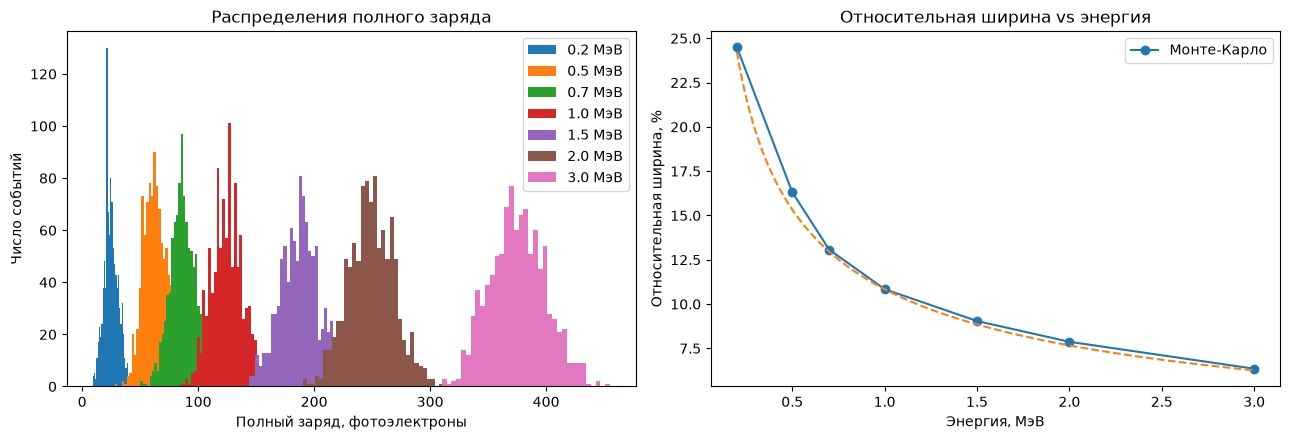

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for energy in energies:
    axes[0].hist(results[energy], bins=35, label=f'{energy} МэВ')
axes[0].set(xlabel='Полный заряд, фотоэлектроны', ylabel='Число событий',
            title='Распределения полного заряда')
axes[0].legend()

axes[1].plot(energies, np.array(relative_widths) * 100, 'o-', label='Монте-Карло')
E_grid = np.linspace(min(energies), max(energies), 200)
axes[1].plot(E_grid, relative_1 * 100 / np.sqrt(E_grid), '--')
axes[1].set(xlabel='Энергия, МэВ', ylabel='Относительная ширина, %',
            title='Относительная ширина vs энергия')
axes[1].legend()
plt.tight_layout()
plt.show()

In [16]:
position_shifted = np.array([0.0, 0.0, 1.0])
charges_shifted = simulate_events(E=1.0, position=position_shifted, n_events=1000)
mean_shifted, std_shifted, rel_shifted = charge_stats(charges_shifted)
change_percent = (mean_shifted - mean_1) / mean_1 * 100

In [17]:
print(f'В центре:            средний Q = {mean_1:.2f} фотоэлектронов')
print(f'При смещении z=1 м:  средний Q = {mean_shifted:.2f} фотоэлектронов')
print(f'Изменение среднего заряда: {change_percent:+.2f}%')
se_difference = np.sqrt(std_1**2 / len(charges_1) + std_shifted**2 / len(charges_shifted))
print(f'Статистическая погрешность разности средних: {se_difference:.2f} фотоэлектронов')

В центре:            средний Q = 125.06 фотоэлектронов
При смещении z=1 м:  средний Q = 124.87 фотоэлектронов
Изменение среднего заряда: -0.15%
Статистическая погрешность разности средних: 0.60 фотоэлектронов


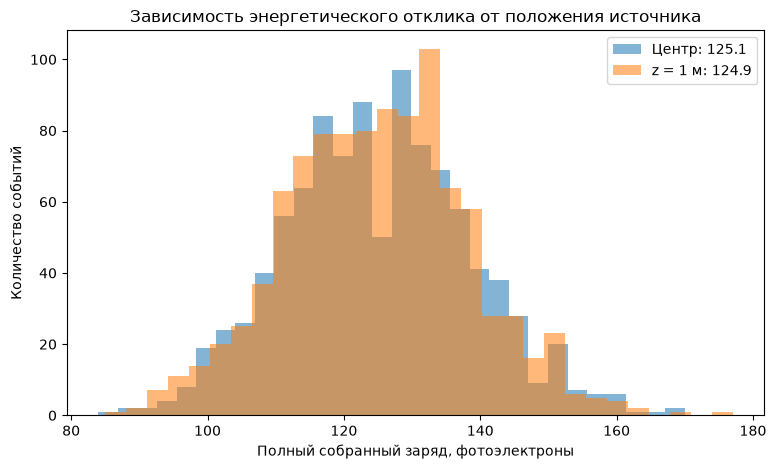

In [18]:
plt.figure(figsize=(9, 5))
plt.hist(charges_1, bins=30, alpha=0.55, label=f'Центр: {mean_1:.1f}')
plt.hist(charges_shifted, bins=30, alpha=0.55, label=f'z = 1 м: {mean_shifted:.1f}')
plt.xlabel('Полный собранный заряд, фотоэлектроны')
plt.ylabel('Количество событий')
plt.title('Зависимость энергетического отклика от положения источника')
plt.legend()
plt.show()

- Относительная ширина уменьшается, так как при увеличении энергии увеличивается в среднем число фотоэлектронов и ширина распредения зависит от энергии как обратный ее квадрат.
- Для источника, смещенного на 1 метр по оси z меняется вероятность попадание фотоэлектронов в ФЭУ и поэтому среднее значение для собранного заряда нельзя принимать равным нулю.